In [1]:
import pandas as pd
df = pd.read_excel("meesho_orders.xlsx")


In [2]:
import pandas as pd

df = pd.read_excel("meesho_orders.xlsx")

# Clean up columns
df.columns = [str(c).strip() for c in df.columns]

# Convert dates
df["ORDER DATE"] = pd.to_datetime(df["ORDER DATE"], errors="coerce", dayfirst=True)
df["EXPECTED PAYMENT DATE"] = pd.to_datetime(df["EXPECTED PAYMENT DATE"], errors="coerce", dayfirst=True)
df["ACTUAL PAYMENT DATE"] = pd.to_datetime(df["ACTUAL PAYMENT DATE"], errors="coerce", dayfirst=True)

# Prices as numbers
df["MEESHO PRICE"] = pd.to_numeric(df["MEESHO PRICE"], errors="coerce").fillna(0)
df["COST PRICE"] = pd.to_numeric(df["COST PRICE"], errors="coerce").fillna(0)

# Profit per order
df["PROFIT"] = df["MEESHO PRICE"] - df["COST PRICE"]

# Headline numbers
total_cost = df["COST PRICE"].sum()
total_profit = df["PROFIT"].sum()
total_meesho = df["MEESHO PRICE"].sum()

print("=== HEADLINE NUMBERS ===")
print(f"Total cost price (inventory money): ₹{total_cost:,.2f}")
print(f"Total Meesho price (sales value):   ₹{total_meesho:,.2f}")
print(f"Total profit (your money):          ₹{total_profit:,.2f}")

# Profit by status
print("\n=== PROFIT BY STATUS ===")
print(df.groupby("ORDER STATUS")["PROFIT"].sum())

# Payment delay analysis
paid = df.dropna(subset=["ACTUAL PAYMENT DATE"]).copy()
if len(paid) > 0:
    paid["DELAY_DAYS"] = (paid["ACTUAL PAYMENT DATE"] - paid["ORDER DATE"]).dt.days
    avg_delay = paid["DELAY_DAYS"].mean()
    print(f"\n=== PAYMENT ANALYSIS ===")
    print(f"Orders with actual payment: {len(paid)}")
    print(f"Average delay (order date -> payment): {avg_delay:.1f} days")
else:
    avg_delay = 8
    print("\nNo actual payment dates yet — using assumed 8-day settlement window.")

# Upcoming payments
today = pd.Timestamp.today().normalize()
pending = df[df["ACTUAL PAYMENT DATE"].isna()].copy()
pending["EST_PAYMENT"] = pending["ORDER DATE"] + pd.Timedelta(days=avg_delay)
upcoming = pending[pending["EST_PAYMENT"] <= today + pd.Timedelta(days=30)]

print(f"\n=== UPCOMING PAYMENTS (next 30 days) ===")
print(f"Pending orders with estimated payout within 30 days: {len(upcoming)}")
print(f"Expected amount: ₹{upcoming['MEESHO PRICE'].sum():,.2f}")

=== HEADLINE NUMBERS ===
Total cost price (inventory money): ₹19,575.00
Total Meesho price (sales value):   ₹26,831.00
Total profit (your money):          ₹7,256.00

=== PROFIT BY STATUS ===


KeyError: 'ORDER STATUS'

In [3]:
print(list(df.columns))

['SNO.', 'SUB ORDER ID', 'PRODUCT', 'MEESHO PRICE', 'COST PRICE', 'ORDER DATE', 'STATUS', 'EXPECTED PAYMENT DATE', 'ACTUAL PAYMENT DATE', 'ACTUAL AMOUNT RECEIVED', 'PROFIT']


In [4]:
print(df.groupby("STATUS")["PROFIT"].sum())

STATUS
DELIVERED              274.0
DELIVERED             4700.0
DELIVERED & RETURN    2282.0
Name: PROFIT, dtype: float64


In [5]:
df["STATUS"] = df["STATUS"].str.strip()
print(df.groupby("STATUS")["PROFIT"].sum())

STATUS
DELIVERED             4974.0
DELIVERED & RETURN    2282.0
Name: PROFIT, dtype: float64


Matplotlib is building the font cache; this may take a moment.


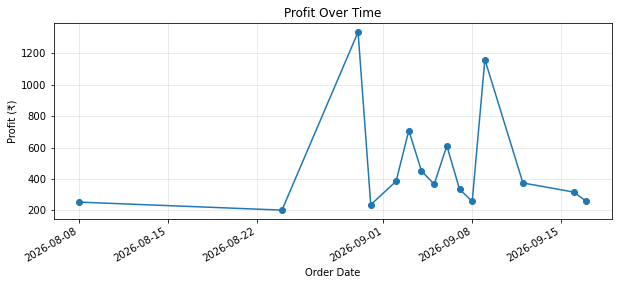

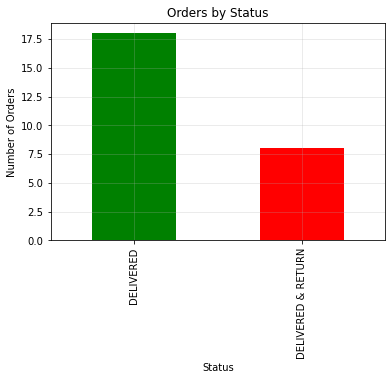

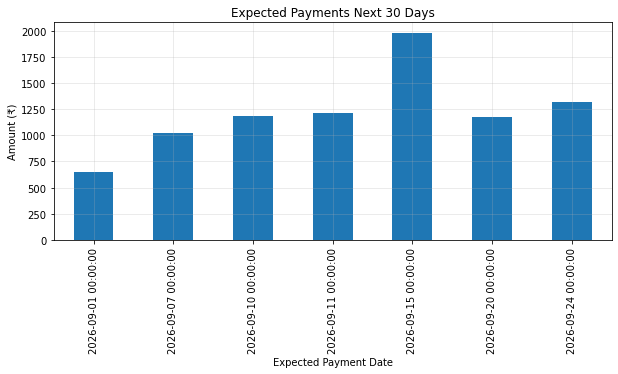

In [6]:
import matplotlib.pyplot as plt

# Make sure dates are datetime
df["ORDER DATE"] = pd.to_datetime(df["ORDER DATE"], errors="coerce", dayfirst=True)

# 1. Profit trend over time (by order date)
profit_by_date = df.groupby("ORDER DATE")["PROFIT"].sum().sort_index()
plt.figure(figsize=(10, 4))
profit_by_date.plot(marker="o")
plt.title("Profit Over Time")
plt.xlabel("Order Date")
plt.ylabel("Profit (₹)")
plt.grid(True, alpha=0.3)
plt.show()

# 2. Status breakdown
status_counts = df["STATUS"].value_counts()
plt.figure(figsize=(6, 4))
status_counts.plot(kind="bar", color=["green", "red", "orange"])
plt.title("Orders by Status")
plt.xlabel("Status")
plt.ylabel("Number of Orders")
plt.grid(True, alpha=0.3)
plt.show()

# 3. Upcoming payments (next 30 days)
avg_delay = 8  # adjust once you have real payment data
pending = df[df["ACTUAL PAYMENT DATE"].isna()].copy()
pending["EST_PAYMENT"] = pd.to_datetime(pending["ORDER DATE"], errors="coerce") + pd.Timedelta(days=avg_delay)
today = pd.Timestamp.today().normalize()
upcoming = pending[pending["EST_PAYMENT"] <= today + pd.Timedelta(days=30)]
upcoming_daily = upcoming.groupby("EST_PAYMENT")["MEESHO PRICE"].sum().sort_index()

plt.figure(figsize=(10, 4))
upcoming_daily.plot(kind="bar")
plt.title("Expected Payments Next 30 Days")
plt.xlabel("Expected Payment Date")
plt.ylabel("Amount (₹)")
plt.grid(True, alpha=0.3)
plt.show()

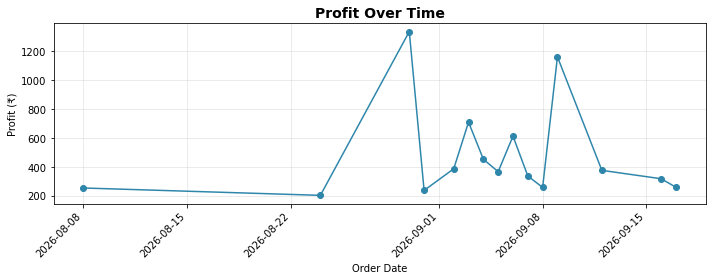

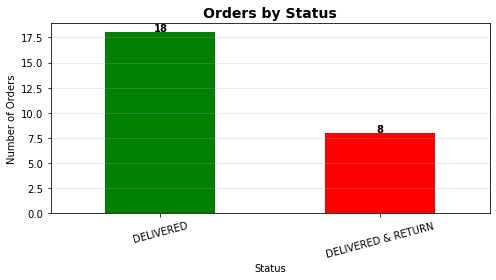

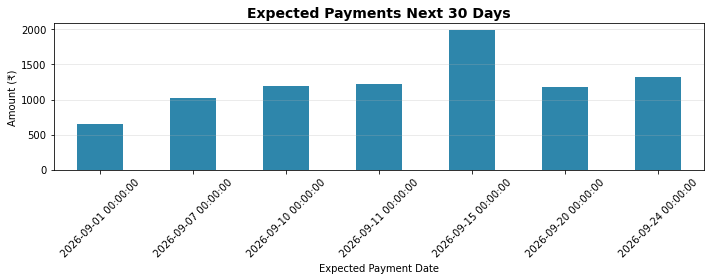

  SIMPLE SUMMARY
Money spent on stock:      ₹19,575.00
Money coming in (sales):   ₹26,831.00
Profit we keep:            ₹7,256.00
Orders delivered:          18
Orders returned:           8


In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# Make sure dates are datetime
df["ORDER DATE"] = pd.to_datetime(df["ORDER DATE"], errors="coerce", dayfirst=True)

# --- 1. Profit trend with cleaner labels ---
profit_by_date = df.groupby("ORDER DATE")["PROFIT"].sum().sort_index()
plt.figure(figsize=(10, 4))
profit_by_date.plot(marker="o", color="#2E86AB")
plt.title("Profit Over Time", fontsize=14, fontweight="bold")
plt.xlabel("Order Date")
plt.ylabel("Profit (₹)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- 2. Status breakdown with rotated labels ---
status_counts = df["STATUS"].value_counts()
plt.figure(figsize=(7, 4))
colors = {"DELIVERED": "green", "DELIVERED & RETURN": "red"}
bars = status_counts.plot(kind="bar", color=[colors.get(s, "gray") for s in status_counts.index])
plt.title("Orders by Status", fontsize=14, fontweight="bold")
plt.xlabel("Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=15)
for i, v in enumerate(status_counts.values):
    plt.text(i, v + 0.1, str(v), ha="center", fontweight="bold")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# --- 3. Expected payments with readable dates ---
avg_delay = 8  # replace with your observed average once you have real data
pending = df[df["ACTUAL PAYMENT DATE"].isna()].copy()
pending["EST_PAYMENT"] = df["ORDER DATE"] + pd.Timedelta(days=avg_delay)
today = pd.Timestamp.today().normalize()
upcoming = pending[pending["EST_PAYMENT"] <= today + pd.Timedelta(days=30)]
upcoming_daily = upcoming.groupby("EST_PAYMENT")["MEESHO PRICE"].sum().sort_index()

plt.figure(figsize=(10, 4))
upcoming_daily.plot(kind="bar", color="#2E86AB")
plt.title("Expected Payments Next 30 Days", fontsize=14, fontweight="bold")
plt.xlabel("Expected Payment Date")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# --- Plain-language summary for your parents ---
total_cost = df["COST PRICE"].sum()
total_profit = df["PROFIT"].sum()
print("=" * 40)
print("  SIMPLE SUMMARY")
print("=" * 40)
print(f"Money spent on stock:      ₹{total_cost:,.2f}")
print(f"Money coming in (sales):   ₹{df['MEESHO PRICE'].sum():,.2f}")
print(f"Profit we keep:            ₹{total_profit:,.2f}")
print(f"Orders delivered:          {int((df['STATUS']=='DELIVERED').sum())}")
print(f"Orders returned:           {int((df['STATUS']=='DELIVERED & RETURN').sum())}")
print("=" * 40)